In [1]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
DATA.mkdir(exist_ok=True)
path = DATA / "active.csv"

# CelesTrak asks for infrequent downloads, so reuse the file if we already have it
if not path.exists():
    url = "https://celestrak.org/NORAD/elements/gp.php?GROUP=active&FORMAT=csv"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    path.write_text(r.text)

df = pd.read_csv(path)
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(16872, 17)


,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,CLASSIFICATION_TYPE,NORAD_CAT_ID,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT
0,CALSPHERE 1,1964-063C,2026-11-06T18:37:39.652032,13.767548,0.002582,90.2232,75.0778,217.2973,238.2917,0,U,900,999,9104,0.000563,5.630000e-06,0.0
1,CALSPHERE 2,1964-063E,2026-11-06T14:58:20.253792,13.529095,0.001902,90.2351,79.1431,168.2090,250.3948,0,U,902,999,87552,0.000066,5.300000e-07,0.0
2,LCS 1,1965-034C,2026-11-06T18:03:16.782048,9.893112,0.001063,32.1373,198.5283,269.3730,90.5550,0,U,1361,999,22400,0.001500,2.000000e-07,0.0
3,TEMPSAT 1,1965-065E,2026-11-06T18:26:38.119200,13.336019,0.006870,90.0125,212.6711,206.9999,219.8333,0,U,1512,999,97905,0.000062,4.000000e-07,0.0
4,CALSPHERE 4A,1965-065H,2026-11-06T19:21:38.314944,13.362991,0.007127,89.8843,120.9989,61.7001,68.3271,0,U,1520,999,98175,0.000176,1.020000e-06,0.0


In [2]:
print(df.columns.tolist())
df[["OBJECT_NAME", "INCLINATION", "ECCENTRICITY", "MEAN_MOTION", "EPOCH"]].describe(include="all")

['OBJECT_NAME', 'OBJECT_ID', 'EPOCH', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'ARG_OF_PERICENTER', 'MEAN_ANOMALY', 'EPHEMERIS_TYPE', 'CLASSIFICATION_TYPE', 'NORAD_CAT_ID', 'ELEMENT_SET_NO', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT']


,OBJECT_NAME,INCLINATION,ECCENTRICITY,MEAN_MOTION,EPOCH
count,16872,16872.000000,16872.000000,16872.000000,16872
unique,16872,NaN,NaN,NaN,11544
top,CALSPHERE 1,NaN,NaN,NaN,2026-11-06T18:00:02.998944
freq,1,NaN,NaN,NaN,1007
mean,NaN,62.355303,0.002382,14.439281,NaN
std,NaN,24.246226,0.035882,2.999394,NaN
min,NaN,0.001200,0.000004,0.284981,NaN
25%,NaN,43.004600,0.000126,15.101898,NaN
50%,NaN,53.159500,0.000157,15.276280,NaN
75%,NaN,87.913300,0.000299,15.343923,NaN


In [ ]:
# derive altitude and period to classify the orbit regime

import numpy as np

required = ["OBJECT_NAME", "NORAD_CAT_ID", "EPOCH", "MEAN_MOTION", "ECCENTRICITY", "INCLINATION"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}. Found: {df.columns.tolist()}"

MU = 398600.4418      # Earth's gravitational parameter, km^3/s^2
R_EARTH = 6378.137    # km

n = df["MEAN_MOTION"] * 2 * np.pi / 86400          # revs/day -> radians/second
df["a_km"] = (MU / n**2) ** (1 / 3)                # semi-major axis
df["period_min"] = 1440 / df["MEAN_MOTION"]
df["mean_alt_km"] = df["a_km"] - R_EARTH
df["perigee_km"] = df["a_km"] * (1 - df["ECCENTRICITY"]) - R_EARTH
df["apogee_km"] = df["a_km"] * (1 + df["ECCENTRICITY"]) - R_EARTH

def regime(row):
    if row["ECCENTRICITY"] > 0.25:
        return "HEO"
    if row["mean_alt_km"] < 2000:
        return "LEO"
    if 1400 <= row["period_min"] <= 1480:
        return "GEO"
    if row["mean_alt_km"] < 35000:
        return "MEO"
    return "Other"

df["regime"] = df.apply(regime, axis=1)
df[["OBJECT_NAME", "mean_alt_km", "period_min", "regime"]].head()

,OBJECT_NAME,mean_alt_km,period_min,regime
0,CALSPHERE 1,975.419660,104.593789,LEO
1,CALSPHERE 2,1061.573065,106.437275,LEO
2,LCS 1,2787.864084,145.555824,MEO
3,TEMPSAT 1,1133.208088,107.978254,LEO
4,CALSPHERE 4A,1123.097161,107.760306,LEO


        count  share_%
regime                
LEO     16058     95.2
GEO       588      3.5
MEO       179      1.1
HEO        46      0.3
Other       1      0.0


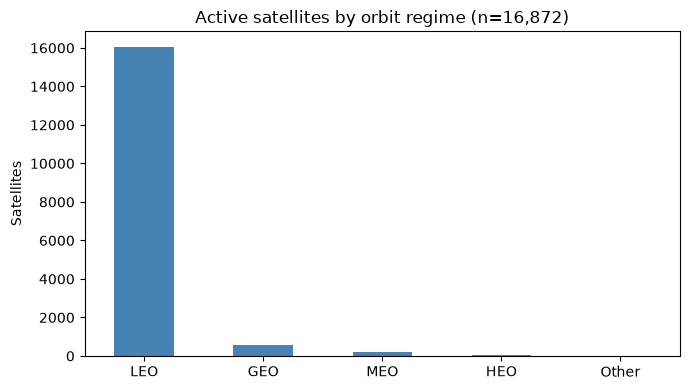

In [ ]:
# count of satellites in each regime
counts = df["regime"].value_counts()
share = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"count": counts, "share_%": share}))

# bar chart of satellites by orbit regime
ax = counts.plot(kind="bar", color="steelblue", figsize=(7, 4))
ax.set_title(f"Active satellites by orbit regime (n={len(df):,})")
ax.set_ylabel("Satellites")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

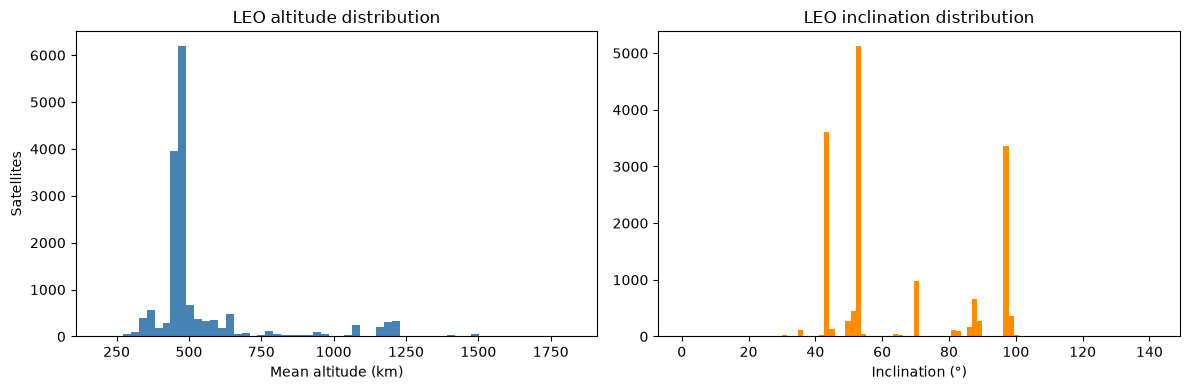

       mean_alt_km  INCLINATION
count      16058.0      16058.0
mean         544.1         64.7
std          209.4         21.7
min          190.5          0.0
25%          462.7         50.0
50%          474.6         53.2
75%          502.6         89.0
max         1829.5        142.0


In [9]:
# altitude and inclination distribution for LEO

leo = df[df["regime"] == "LEO"] # boolean mask pattern for LEO satellites

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(leo["mean_alt_km"], bins=60, color="steelblue")
axes[0].set_title("LEO altitude distribution")
axes[0].set_xlabel("Mean altitude (km)")
axes[0].set_ylabel("Satellites")

axes[1].hist(leo["INCLINATION"], bins=90, color="darkorange")
axes[1].set_title("LEO inclination distribution")
axes[1].set_xlabel("Inclination (°)")
plt.tight_layout()
plt.show()

print(leo[["mean_alt_km", "INCLINATION"]].describe().round(1))

Starlink: 11,204 of 16,058 LEO satellites (69.8%)

Top Starlink inclinations (°):
INCLINATION
53.0    5073
43.0    3606
97.0    1513
70.0     978
31.0      22
98.0       8
Name: count, dtype: int64


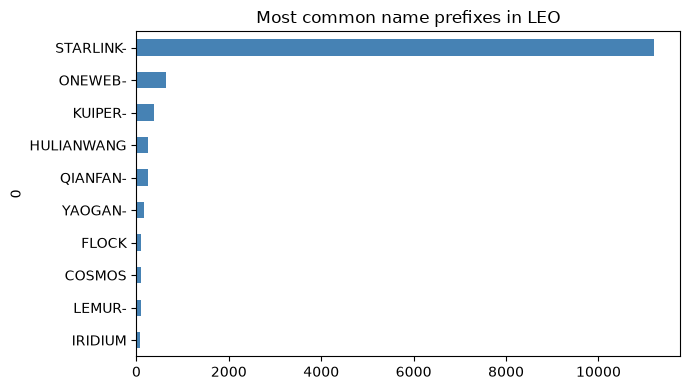

In [10]:
df["is_starlink"] = df["OBJECT_NAME"].str.upper().str.contains("STARLINK") # filter for starlink (boolean)
leo = df[df["regime"] == "LEO"] # filter for LEO

n_star = int(leo["is_starlink"].sum()) # summing boolean values for a total count
print(f"Starlink: {n_star:,} of {len(leo):,} LEO satellites "
      f"({n_star / len(leo) * 100:.1f}%)")

star_incl = leo[leo["is_starlink"]]["INCLINATION"].round(0).value_counts().head(6)
print("\nTop Starlink inclinations (°):")
print(star_incl)

top_names = (
    leo["OBJECT_NAME"].str.extract(r"^([A-Za-z\-]+)")[0]
    .str.upper().value_counts().head(10)
)
top_names.plot(kind="barh", figsize=(7, 4), color="steelblue").invert_yaxis()
plt.title("Most common name prefixes in LEO")
plt.tight_layout()
plt.show()

Excluded 1 future-dated element set(s): ['CXO']
count    16871.00
mean         0.69
std          0.80
min          0.21
25%          0.43
50%          0.58
75%          0.76
max         28.88
Name: age_days, dtype: float64

Older than 3 days: 0.5%
Older than 7 days: 0.1%


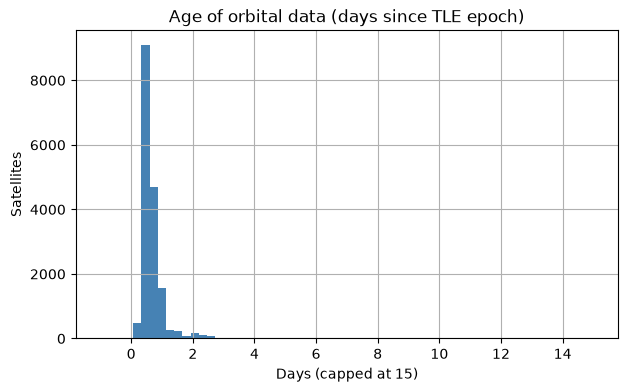

In [13]:
df["epoch_dt"] = pd.to_datetime(df["EPOCH"], utc=True)
now = pd.Timestamp.now(tz="UTC")
df["age_days"] = (now - df["epoch_dt"]).dt.total_seconds() / 86400

future = df[df["age_days"] < 0]
print(f"Excluded {len(future)} future-dated element set(s): {future['OBJECT_NAME'].tolist()}")
age = df.loc[df["age_days"] >= 0, "age_days"]
print(age.describe().round(2))
print(f"\nOlder than 3 days: {(age > 3).mean() * 100:.1f}%")
print(f"Older than 7 days: {(age > 7).mean() * 100:.1f}%")

df["age_days"].clip(upper=15).hist(bins=60, figsize=(7, 4), color="steelblue")
plt.title("Age of orbital data (days since TLE epoch)")
plt.xlabel("Days (capped at 15)")
plt.ylabel("Satellites")
plt.show()

In [ ]:
mid = df[(df["regime"] == "LEO") & df["mean_alt_km"].between(1050, 1250)]
print(len(mid))
print(mid["OBJECT_NAME"].str.extract(r"^([A-Za-z\-]+)")[0].str.upper().value_counts().head(8))

1142
0
ONEWEB-       648
HULIANWANG    232
QIANFAN-      198
YAOGAN-        35
CHUANGXIN       4
CALSPHERE       2
KL-ALPHA        2
RSW-            2
Name: count, dtype: int64


In [15]:
low = df[(df["regime"] == "LEO") & df["mean_alt_km"].between(450, 500)]
print(len(low), f"{low['is_starlink'].mean() * 100:.1f}% Starlink")

10118 93.9% Starlink


# Active Satellite Catalog Analysis

**Research question:** How is the active satellite population distributed across orbital regimes, how concentrated is it among operators, and how reliable is the orbital data used for position prediction?

1. What share of active satellites occupies each orbital regime (LEO, MEO, GEO, HEO)?
2. How concentrated is the LEO population by operator, altitude, and inclination?
3. How current is the underlying element-set data, and what does that imply for prediction accuracy?

**Data:** CelesTrak `active` group (GP data, CSV), downloaded November 6, 2026. n = 16,872 satellites.

## Methods and definitions

Orbital quantities are derived from each satellite's mean motion and eccentricity using Kepler's third law (μ = 398,600.4418 km³/s², Earth radius = 6,378.137 km). Because this is a simplified two-body calculation, altitudes can differ slightly from SGP4 values.

| Term | Definition |
|---|---|
| Semi-major axis (a) | (μ / n²)^(1/3), where n is mean motion in rad/s |
| Mean altitude | a − Earth radius |
| Period | 1440 / mean motion (minutes) |
| **HEO** (highly elliptical) | ==Eccentricity > 0.25== |
| **LEO** (low Earth orbit) | Not HEO, ==mean altitude < 2,000 km== |
| **GEO** (geosynchronous) | Not HEO or LEO, ==period between 1,400 and 1,480 min== (about 24 h) |
| **MEO** (medium Earth orbit) | Not HEO, LEO, or GEO, ==mean altitude < 35,000 km== |
| **Other** | Anything else |
| Starlink | Object name contains "STARLINK" |
| TLE age | Now minus element-set epoch, in days |

Regimes are assigned in the order shown. The cutoffs are my own definitions (standard conventions, but not the only ones), so the shares below depend on them.

**Scope:** the `active` group excludes debris and spent rocket bodies, so this describes working satellites, not everything in orbit. One satellite (CXO, the Chandra X-ray Observatory) has an element-set epoch about one day in the future; it is excluded from the age statistics.

## Findings

1. **LEO dominates.** 16,058 of 16,872 active satellites (95.2%) are in LEO, followed by GEO (588, 3.5%), MEO (179, 1.1%), and HEO (46, 0.3%). One object fell in "Other."
2. **One operator is most of LEO.** Starlink accounts for 11,204 of 16,058 LEO satellites (69.8%). The next largest groups (OneWeb, Kuiper, and several Chinese constellations) are far smaller.
3. **LEO inclinations form distinct clusters, driven largely by Starlink.** The tallest clusters are near 53°, 43°, and 97°, with smaller clusters near 70° and 85–90°. Starlink's four main inclinations (53°: 5,073; 43°: 3,606; 97°: 1,513; 70°: 978) cover about 11,170 satellites, nearly its entire fleet, so the shape of this distribution mostly reflects one company's orbital design choices rather than a natural spread.
4. **LEO altitude is concentrated, in two tiers.** The median mean altitude is about 475 km, and 10,118 LEO satellites sit in the 450–500 km band, 93.9% of them Starlink. A second group sits at 1,050–1,250 km: of those 1,142 satellites, 94% belong to three constellations (OneWeb 648, Hulianwang 232, Qianfan 198). So the LEO population splits into a low, crowded tier dominated by one operator and a higher tier used by competing constellations.
5. **Orbital data is fresh.** The median element set is 0.56 days old; 0.5% are older than 3 days and 0.1% are older than 7 days. This supports the accuracy of the tracker for the main catalog, since SGP4 position error grows as the element set ages.

## Implications

- **Concentration:** about 70% of the LEO population belongs to a single operator, so congestion and collision-avoidance concerns in LEO are largely concerns about one constellation's behavior.
- **Altitude crowding:** a single 50 km band (450–500 km) holds about 63% of all LEO satellites, which is where crowding is highest.
- **For the tracker app:** a satellite list for the full catalog would be dominated by Starlink, which is why the app offers group, name, inclination, and period filters and caps the map at 200 markers.

## Limitations

- Regime shares depend on the cutoffs above.
- This is a single snapshot taken on November 6, 2026; satellite counts change daily as launches and deorbits occur.
- Name-based grouping (e.g. "STARLINK") assumes consistent naming in the source data.
- Findings describe density and composition, not collision risk.

In [17]:
import sys, time
from datetime import datetime, timezone
from math import radians, sin, cos, asin, sqrt

sys.path.insert(0, "..")         
from app.tle import load_group, ts
from skyfield.api import wgs84

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = radians(lat1), radians(lat2)
    a = sin((p2 - p1) / 2) ** 2 + cos(p1) * cos(p2) * sin(radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371 * asin(sqrt(a))

iss = load_group("stations")[25544]
rows = []
for _ in range(10):
    ref = requests.get("https://api.wheretheiss.at/v1/satellites/25544", timeout=15).json()
    t = ts.from_datetime(datetime.fromtimestamp(ref["timestamp"], tz=timezone.utc))
    geo = iss.at(t)
    lat, lon = wgs84.latlon_of(geo)
    rows.append({
        "dist_km": haversine_km(lat.degrees, lon.degrees, ref["latitude"], ref["longitude"]),
        "alt_diff_km": wgs84.height_of(geo).km - ref["altitude"],
    })
    time.sleep(2)               

pos = pd.DataFrame(rows)
print(pos.describe().round(2))

       dist_km  alt_diff_km
count    10.00        10.00
mean      5.85        -0.06
std       0.00         0.00
min       5.85        -0.06
25%       5.85        -0.06
50%       5.85        -0.06
75%       5.85        -0.06
max       5.85        -0.06


In [21]:
ref = requests.get("https://api.wheretheiss.at/v1/satellites/25544", timeout=15).json()
print(ref["timestamp"])
time.sleep(5)
ref = requests.get("https://api.wheretheiss.at/v1/satellites/25544", timeout=15).json()
print(ref["timestamp"])

1794026560
1794026566


In [24]:
print(f"Ground-position difference: mean {pos['dist_km'].mean():.1f} km, "
      f"max {pos['dist_km'].max():.1f} km (n={len(pos)})")

Ground-position difference: mean 5.8 km, max 5.8 km (n=10)


In [ ]:
from app import tracker

LAT, LON = 37.34, -121.89
TZ = "America/Los_Angeles"

# (date, start, highest point, max alt, type) from Heavens-Above "all passes"
# type: v = visible, n = night (unlit), d = daylight
ref_all = [
    ("2026-11-06","02:53:01","02:56:07",33,"n"), ("2026-11-06","04:30:01","04:32:49",24,"v"),
    ("2026-11-06","19:34:51","19:37:48",30,"v"), ("2026-11-06","21:11:40","21:14:35",27,"n"),
    ("2026-11-07","02:05:37","02:08:21",22,"n"), ("2026-11-07","03:42:02","03:45:16",43,"n"),
    ("2026-11-07","18:48:03","18:50:17",17,"v"), ("2026-11-07","20:23:37","20:26:50",43,"n"),
    ("2026-11-07","22:03:25","22:04:20",11,"n"),
    ("2026-11-08","01:18:18","01:20:29",16,"n"), ("2026-11-08","02:54:16","02:57:39",83,"n"),
    ("2026-11-08","19:35:47","19:39:06",77,"v"), ("2026-11-08","21:14:31","21:16:22",14,"n"),
    ("2026-11-09","00:31:08","00:32:33",12,"n"), ("2026-11-09","02:06:37","02:09:57",54,"n"),
    ("2026-11-09","03:44:37","03:46:24",14,"n"), ("2026-11-09","18:48:10","18:51:26",56,"v"),
    ("2026-11-09","20:25:58","20:28:27",19,"n"),
    ("2026-11-10","01:19:04","01:22:09",32,"n"), ("2026-11-10","02:56:03","02:58:51",24,"n"),
    ("2026-11-10","18:00:50","18:03:47",29,"v"), ("2026-11-10","19:37:38","19:40:34",27,"v"),
    ("2026-11-11","00:31:35","00:34:17",22,"n"), ("2026-11-11","02:07:58","02:11:13",44,"n"),
    ("2026-11-11","17:13:59","17:16:11",17,"d"), ("2026-11-11","18:49:30","18:52:42",44,"v"),
    ("2026-11-11","20:29:16","20:30:12",11,"n"), ("2026-11-11","23:44:11","23:46:20",16,"n"),
    ("2026-11-12","01:20:07","01:23:30",84,"n"), ("2026-11-12","18:01:35","18:04:54",79,"v"),
    ("2026-11-12","19:40:17","19:42:09",14,"v"), ("2026-11-12","22:56:57","22:58:18",12,"n"),
    ("2026-11-13","00:32:24","00:35:42",53,"n"), ("2026-11-13","02:10:21","02:12:09",14,"n"),
    ("2026-11-13","17:13:53","17:17:08",54,"d"), ("2026-11-13","18:51:39","18:54:09",19,"v"),
    ("2026-11-13","23:44:46","23:47:50",32,"n"),
    ("2026-11-14","01:21:43","01:24:31",24,"n"), ("2026-11-14","16:26:30","16:29:25",29,"d"),
    ("2026-11-14","18:03:14","18:06:10",28,"v"), ("2026-11-14","22:57:12","22:59:53",21,"n"),
    ("2026-11-15","00:33:34","00:36:48",45,"n"), ("2026-11-15","15:39:34","15:41:43",16,"d"),
    ("2026-11-15","17:15:01","17:18:13",44,"d"), ("2026-11-15","18:54:45","18:55:43",11,"v"),
    ("2026-11-15","22:09:44","22:11:50",15,"n"), ("2026-11-15","23:45:38","23:49:00",86,"n"),
]

mine = tracker.passes(iss, LAT, LON, days=10, min_elev=10)
rises = pd.to_datetime([p["rise"] for p in mine], utc=True)
peaks = pd.to_datetime([p["peak"] for p in mine], utc=True)

def to_utc(date, hms):
    return pd.Timestamp(f"{date} {hms}").tz_localize(TZ).tz_convert("UTC")

pad = pd.Timedelta(minutes=5)
rows = []
for date, start, peak, alt, kind in ref_all:
    pk = to_utc(date, peak)
    if pk < peaks.min() - pad or pk > peaks.max() + pad:
        continue                          # outside the window my app searched
    d = (peaks - pk).total_seconds()
    i = int(np.argmin(np.abs(d)))
    ok = abs(d[i]) <= 600
    rows.append({
        "date": date, "type": kind, "matched": ok,
        "rise_diff_s": (rises[i] - to_utc(date, start)).total_seconds() if ok else None,
        "peak_diff_s": d[i] if ok else None,
        "alt_diff_deg": mine[i]["max_elev_deg"] - alt if ok else None,
    })

val = pd.DataFrame(rows)
m = val[val["matched"]]
site_end = to_utc("2026-11-16", "00:00:00")
print(f"Site passes in my search window: {len(val)}; matched: {len(m)}")
print(f"My app listed {int((peaks <= site_end).sum())} passes within the site's date range")
for col, unit in [("rise_diff_s", "s"), ("peak_diff_s", "s"), ("alt_diff_deg", "deg")]:
    x = m[col].astype(float)
    print(f"{col}: mean |diff| {x.abs().mean():.2f} {unit}, max {x.abs().max():.2f} {unit}")
print("\nPass types (site's classification):")
print(val["type"].map({"v": "visible", "n": "night (unlit)", "d": "daylight"}).value_counts())

Site passes in my search window: 44; matched: 44
My app listed 44 passes within the site's date range
rise_diff_s: mean |diff| 0.68 s, max 1.00 s
peak_diff_s: mean |diff| 0.41 s, max 1.00 s
alt_diff_deg: mean |diff| 0.22 deg, max 0.50 deg

Pass types (site's classification):
type
night (unlit)    28
visible          11
daylight          5
Name: count, dtype: int64


## Validation

**Position check:** compared the app's ISS position with the wheretheiss.at API at the API's own timestamps (10 readings). Ground-position difference was 5.8 km, stable across readings, which is under one second (about 0.75 s) of orbital motion. The stable offset suggests a small systematic difference (e.g., element-set epoch), not random error.

**Pass-time check:** compared every predicted ISS pass over San Jose (37.34, -121.89) with Heavens-Above's full pass list (including non-visible passes) for a 10-day window (6 to 15 Nov. 2026). All 44 site passes had a matching prediction, and the app listed no extra passes. Rise time (10° elevation crossing): mean absolute difference 0.68 s, max 1.0 s. Peak time: mean 0.41 s, max 1.0 s. Peak elevation: mean 0.22°, max 0.5°. These differences are at the resolution of the source, which reports whole seconds and degrees.

**Pass visibility:** only 11 of 44 passes (25%) were classed as visible by Heavens-Above; 28 occurred while the ISS was in Earth's shadow (night, unlit) and 5 in daylight. The app lists geometric passes, not visibility.

**Caveat:** both sources run SGP4 on public orbital elements (the site's element set is dated 6 November), so this validates my implementation (time handling, coordinate conversion, pass detection), not the accuracy of the element sets themselves.